In [1]:
!pip install -q ultralytics

In [2]:
import os
import cv2
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glob import glob
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Seed Fixed")

Seed Fixed


In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cuda


In [10]:
# ==========================
# BDD100K
# ==========================

BDD_IMAGE_ROOT = "/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k"

BDD_TRAIN_IMAGES = os.path.join(BDD_IMAGE_ROOT, "train")
BDD_VAL_IMAGES   = os.path.join(BDD_IMAGE_ROOT, "val")

BDD_LABEL_ROOT = "/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k_labels_release/bdd100k/labels"

BDD_TRAIN_JSON = os.path.join(
    BDD_LABEL_ROOT,
    "bdd100k_labels_images_train.json"
)

BDD_VAL_JSON = os.path.join(
    BDD_LABEL_ROOT,
    "bdd100k_labels_images_val.json"
)

# ==========================
# ACDC
# ==========================

ACDC_ROOT = "/kaggle/input/datasets/yuetoken12/15-9gdiedie/rgb_anon"

print("Paths Loaded Successfully")

Paths Loaded Successfully


In [11]:
weather_classes = {
    "clear":0,
    "partly cloudy":1,
    "overcast":2,
    "foggy":3,
    "rainy":4,
    "snowy":5
}

idx_to_class = {
    v:k
    for k,v in weather_classes.items()
}

NUM_CLASSES = len(weather_classes)

print(weather_classes)

{'clear': 0, 'partly cloudy': 1, 'overcast': 2, 'foggy': 3, 'rainy': 4, 'snowy': 5}


In [23]:
def load_bdd(json_path, image_folder):

    with open(json_path, "r") as f:
        labels = json.load(f)

    rows = []

    missing = 0

    for item in labels:

        weather = item["attributes"]["weather"]

        if weather not in weather_classes:
            continue

        image_path = os.path.join(
            image_folder,
            item["name"]
        )

        if not os.path.exists(image_path):
            missing += 1
            continue

        rows.append({
            "image_path": image_path,
            "weather": weather,
            "label": weather_classes[weather]
        })

    print("Missing Images :", missing)

    return pd.DataFrame(rows)

In [24]:
train_bdd = load_bdd(
    BDD_TRAIN_JSON,
    BDD_TRAIN_IMAGES
)

val_bdd = load_bdd(
    BDD_VAL_JSON,
    BDD_VAL_IMAGES
)

bdd_df = pd.concat(
    [train_bdd,val_bdd],
    ignore_index=True
)

print("BDD Images :",len(bdd_df))

bdd_df.head()

Missing Images : 60727
Missing Images : 0
BDD Images : 9860


,image_path,weather,label
0,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
1,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
2,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
3,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
4,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0


In [26]:
rows=[]

mapping={
    "fog":"foggy",
    "rain":"rainy",
    "snow":"snowy",
    "night":"clear"
}

for folder,label in mapping.items():

    images=glob(
        os.path.join(
            ACDC_ROOT,
            folder,
            "**",
            "*.png"
        ),
        recursive=True
    )

    for img in images:

        rows.append({
            "image_path":img,
            "weather":label,
            "label":weather_classes[label]
        })

acdc_df=pd.DataFrame(rows)

print("ACDC Images :",len(acdc_df))

acdc_df.head()

ACDC Images : 8012


,image_path,weather,label
0,/kaggle/input/datasets/yuetoken12/15-9gdiedie/...,foggy,3
1,/kaggle/input/datasets/yuetoken12/15-9gdiedie/...,foggy,3
2,/kaggle/input/datasets/yuetoken12/15-9gdiedie/...,foggy,3
3,/kaggle/input/datasets/yuetoken12/15-9gdiedie/...,foggy,3
4,/kaggle/input/datasets/yuetoken12/15-9gdiedie/...,foggy,3


In [30]:
combined_df=pd.concat(
    [
        bdd_df,
        acdc_df
    ],
    ignore_index=True
)

print("="*60)
print("BDD :",len(bdd_df))
print("ACDC :",len(acdc_df))
print("TOTAL :",len(combined_df))
print("="*60)

combined_df.head()

BDD : 9860
ACDC : 8012
TOTAL : 17872


,image_path,weather,label
0,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
1,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
2,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
3,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0
4,/kaggle/input/datasets/solesensei/solesensei_b...,clear,0


In [29]:
print("BDD Images :", len(bdd_df))

BDD Images : 9860


In [31]:
train_df, val_df = train_test_split(
    combined_df,
    test_size=0.20,
    random_state=42,
    stratify=combined_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("="*60)
print("Train Images :", len(train_df))
print("Validation Images :", len(val_df))
print("="*60)

print("\nTraining Distribution")
print(train_df["weather"].value_counts())

print("\nValidation Distribution")
print(val_df["weather"].value_counts())

Train Images : 14297
Validation Images : 3575

Training Distribution
weather
clear            6426
snowy            2305
rainy            2284
foggy            1613
overcast         1050
partly cloudy     619
Name: count, dtype: int64

Validation Distribution
weather
clear            1607
snowy             576
rainy             571
foggy             403
overcast          263
partly cloudy     155
Name: count, dtype: int64


In [18]:
IMAGE_SIZE = 224

BATCH_SIZE = 64

EPOCHS = 10

LEARNING_RATE = 1e-4

NUM_WORKERS = 2

PIN_MEMORY = True

In [19]:
train_transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_transform = transforms.Compose([

    transforms.ToPILImage(),

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [32]:
class WeatherDataset(Dataset):

    def __init__(self,dataframe,transform=None):

        self.df = dataframe.reset_index(drop=True)

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self,idx):

        image_path = self.df.loc[idx,"image_path"]

        label = int(self.df.loc[idx,"label"])

        image = cv2.imread(image_path)

        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        if self.transform:
            image = self.transform(image)

        return image,label

In [33]:
train_dataset = WeatherDataset(
    train_df,
    train_transform
)

val_dataset = WeatherDataset(
    val_df,
    val_transform
)

print("Train :",len(train_dataset))
print("Validation :",len(val_dataset))

Train : 14297
Validation : 3575


In [34]:
image,label = train_dataset[0]

print(image.shape)

print(idx_to_class[label])

torch.Size([3, 224, 224])
clear


In [35]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)

        )

    def forward(self, x):

        return self.block(x)

In [36]:
class ResidualBlock(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.conv1 = ConvBlock(channels, channels)

        self.conv2 = nn.Sequential(

            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(channels)

        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):

        identity = x

        out = self.conv1(x)

        out = self.conv2(out)

        out += identity

        out = self.relu(out)

        return out

In [37]:
class SEBlock(nn.Module):

    def __init__(self, channels, reduction=16):

        super().__init__()

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(

            nn.Linear(
                channels,
                channels // reduction
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                channels // reduction,
                channels
            ),

            nn.Sigmoid()

        )

    def forward(self, x):

        b, c, _, _ = x.size()

        y = self.pool(x).view(b, c)

        y = self.fc(y).view(b, c, 1, 1)

        return x * y

In [38]:
class FeatureBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            ConvBlock(
                in_channels,
                out_channels,
                stride=2
            ),

            ResidualBlock(out_channels),

            SEBlock(out_channels)

        )

    def forward(self, x):

        return self.block(x)

In [39]:
class WeatherNet(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.stem = ConvBlock(3, 32)

        self.layer1 = FeatureBlock(32, 64)

        self.layer2 = FeatureBlock(64, 128)

        self.layer3 = FeatureBlock(128, 256)

        self.layer4 = FeatureBlock(256, 512)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.30)

        self.fc = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):

        x = self.stem(x)

        x = self.layer1(x)

        x = self.layer2(x)

        x = self.layer3(x)

        x = self.layer4(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

In [40]:
model = WeatherNet(
    num_classes=NUM_CLASSES
).to(device)

print(model)

WeatherNet(
  (stem): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
  )
  (layer1): FeatureBlock(
    (block): Sequential(
      (0): ConvBlock(
        (block): Sequential(
          (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
      )
      (1): ResidualBlock(
        (conv1): ConvBlock(
          (block): Sequential(
            (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
        )
        (conv2): Sequential(
          (0): Co

In [41]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    patience=2,
    factor=0.5
)

print("Optimizer Ready")

Optimizer Ready


In [42]:
dummy = torch.randn(
    2,
    3,
    224,
    224
).to(device)

output = model(dummy)

print(output.shape)

torch.Size([2, 6])


In [53]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100*correct/total:.2f}%"
        )

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [54]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0

    correct = 0

    total = 0

    predictions = []

    targets = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

            predictions.extend(predicted.cpu().numpy())

            targets.extend(labels.cpu().numpy())

    loss = running_loss / len(loader)

    acc = 100 * correct / total

    return loss, acc, predictions, targets

In [57]:
best_accuracy = 0

train_losses = []

val_losses = []

train_accuracies = []

val_accuracies = []

In [51]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("="*60)
print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))
print("="*60)

Train Batches : 223
Validation Batches : 56


In [58]:
for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc, predictions, targets = validate(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_acc)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print("="*60)

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print(f"Train Loss : {train_loss:.4f}")

    print(f"Train Accuracy : {train_acc:.2f}%")

    print(f"Validation Loss : {val_loss:.4f}")

    print(f"Validation Accuracy : {val_acc:.2f}%")

    if val_acc > best_accuracy:

        best_accuracy = val_acc

        torch.save(
            model.state_dict(),
            "WeatherNet_BDD100K_ACDC_Best.pth"
        )

        print("Best Model Saved")

    print("="*60)

Training:   0%|          | 0/223 [00:00<?, ?it/s]

Epoch 1/10
Train Loss : 0.9304
Train Accuracy : 66.46%
Validation Loss : 0.8689
Validation Accuracy : 68.90%
Best Model Saved


Training:   0%|          | 0/223 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783df44f42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783df44f42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2/10
Train Loss : 0.8314
Train Accuracy : 69.95%
Validation Loss : 0.8312
Validation Accuracy : 70.32%
Best Model Saved


Training:   0%|          | 0/223 [00:00<?, ?it/s]

... (19 outputs left out)

Epoch 9/10
Train Loss : 0.6023
Train Accuracy : 78.51%
Validation Loss : 0.6236
Validation Accuracy : 76.73%


Training:   0%|          | 0/223 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783df44f42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783df44f42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10
Train Loss : 0.5842
Train Accuracy : 78.74%
Validation Loss : 0.5751
Validation Accuracy : 79.44%


In [59]:
model.load_state_dict(

    torch.load(

        "WeatherNet_BDD100K_ACDC_Best.pth",

        map_location=device

    )

)

model.eval()

print("Best Model Loaded")

Best Model Loaded


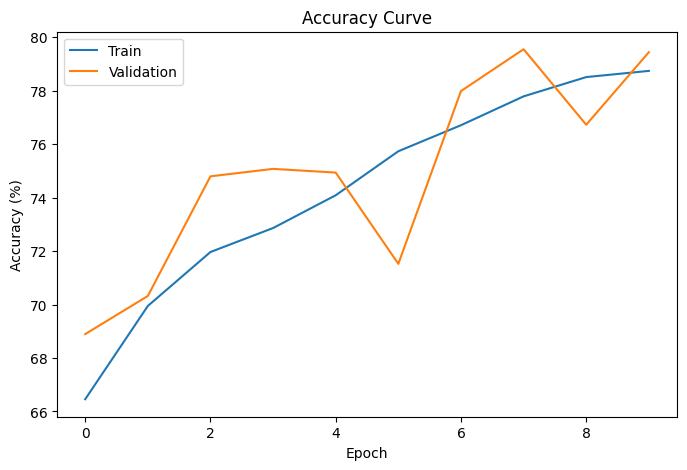

In [60]:
plt.figure(figsize=(8,5))

plt.plot(train_accuracies,label="Train")

plt.plot(val_accuracies,label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Accuracy Curve")

plt.legend()

plt.show()

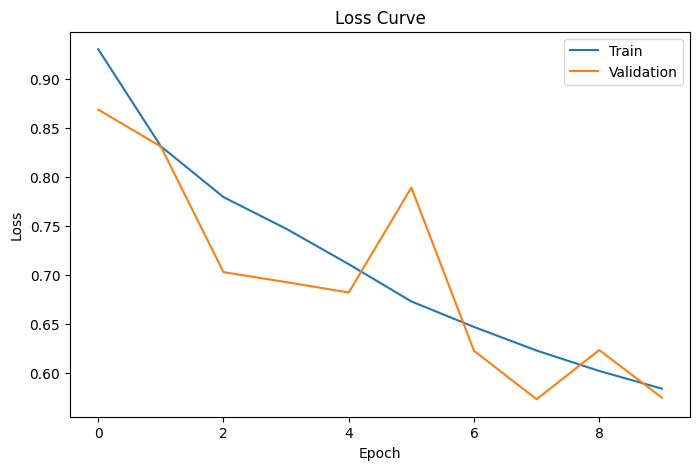

In [61]:
plt.figure(figsize=(8,5))

plt.plot(train_losses,label="Train")

plt.plot(val_losses,label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Loss Curve")

plt.legend()

plt.show()

In [63]:
import seaborn as sns

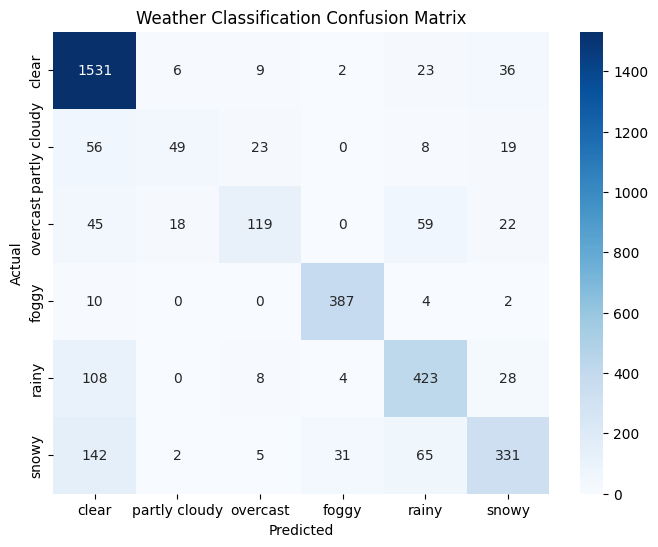

In [64]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    targets,
    predictions
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=idx_to_class.values(),
    yticklabels=idx_to_class.values()
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Weather Classification Confusion Matrix")

plt.show()

In [65]:
from sklearn.metrics import classification_report

print(

classification_report(

targets,

predictions,

target_names=list(idx_to_class.values())

)

)

               precision    recall  f1-score   support

        clear       0.81      0.95      0.88      1607
partly cloudy       0.65      0.32      0.43       155
     overcast       0.73      0.45      0.56       263
        foggy       0.91      0.96      0.94       403
        rainy       0.73      0.74      0.73       571
        snowy       0.76      0.57      0.65       576

     accuracy                           0.79      3575
    macro avg       0.76      0.67      0.70      3575
 weighted avg       0.79      0.79      0.78      3575



In [66]:
torch.save(

model.state_dict(),

"WeatherNet_BDD100K_ACDC_Final.pth"

)

print("Training Completed Successfully")

Training Completed Successfully
